<a href="https://colab.research.google.com/github/nisabulut/digital-image-processing/blob/main/4_7_goruntu_isleme.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [18]:
%%writefile canny_karsilastirma.cpp
#include <opencv2/opencv.hpp>
#include <iostream>
#include <chrono>

using namespace cv;
using namespace std;
using namespace std::chrono;

int main(int argc, char** argv) {
    if (argc != 2) {
        cout << "Kullanım: ./canny_program <test>" << endl;
        return -1;
    }

    // 1. Görüntüyü gri tonlamalı oku
    Mat image = imread(argv[1], IMREAD_GRAYSCALE);
    if (image.empty()) {
        cout << "HATA: Görüntü okunamadı! Lütfen dosya adını kontrol edin." << endl;
        return -1;
    }

    // Gürültüyü azaltmak için hafif bir Gauss
    Mat blurred_image;
    GaussianBlur(image, blurred_image, Size(3, 3), 0, 0);

    // ==========================================
    // TEST 1: SOBEL FİLTRESİ (Çalışma Zamanı Referansı)
    // ==========================================
    Mat sobel_x, sobel_y, sobel_edges;
    auto start_sobel = high_resolution_clock::now();

    Sobel(blurred_image, sobel_x, CV_16S, 1, 0, 3);
    Sobel(blurred_image, sobel_y, CV_16S, 0, 1, 3);
    convertScaleAbs(sobel_x, sobel_x);
    convertScaleAbs(sobel_y, sobel_y);
    addWeighted(sobel_x, 0.5, sobel_y, 0.5, 0, sobel_edges);

    auto end_sobel = high_resolution_clock::now();
    duration<double, std::milli> sobel_time = end_sobel - start_sobel;

    // ==========================================
    // TEST 2: CANNY KENAR TESPİTİ
    // ==========================================
    Mat canny_edges;
    auto start_canny = high_resolution_clock::now();

    // Canny parametreleri: Giriş, Çıkış, Alt Eşik, Üst Eşik (Genelde 1:2 veya 1:3 oranı kullanılır)
    Canny(blurred_image, canny_edges, 50, 150);

    auto end_canny = high_resolution_clock::now();
    duration<double, std::milli> canny_time = end_canny - start_canny;

    // 2. Canny sonucunu kaydet
    imwrite("canny_sonuc.jpg", canny_edges);

    // 3. Süreleri Ekrana Yazdır
    cout << "=================================================" << endl;
    cout << " ÇALIŞMA ZAMANI (PERFORMANS) KIYASLAMASI" << endl;
    cout << "=================================================" << endl;
    cout << "Sobel (1. Derece Turev) Suresi : " << sobel_time.count() << " ms" << endl;
    cout << "Canny Algoritmasi Suresi       : " << canny_time.count() << " ms" << endl;
    cout << "-------------------------------------------------" << endl;
    cout << "NOT: Canny çok aşamalı (Multi-stage) bir algoritma " << endl;
    cout << "oldugu icin her zaman Sobel'den daha uzun surer." << endl;
    cout << "=================================================" << endl;

    return 0;
}

Overwriting canny_karsilastirma.cpp


In [19]:
!apt-get install libopencv-dev -y > /dev/null 2>&1


!g++ canny_karsilastirma.cpp -o canny_program `pkg-config --cflags --libs opencv4`

!./canny_program "test"

 ÇALIŞMA ZAMANI (PERFORMANS) KIYASLAMASI
Sobel (1. Derece Turev) Suresi : 0.70792 ms
Canny Algoritmasi Suresi       : 4.21285 ms
-------------------------------------------------
NOT: Canny çok aşamalı (Multi-stage) bir algoritma 
oldugu icin her zaman Sobel'den daha uzun surer.


In [20]:

!g++ canny_karsilastirma.cpp -o canny_program `pkg-config --cflags --libs opencv4`

!./canny_program "test"

 ÇALIŞMA ZAMANI (PERFORMANS) KIYASLAMASI
Sobel (1. Derece Turev) Suresi : 0.613039 ms
Canny Algoritmasi Suresi       : 2.65395 ms
-------------------------------------------------
NOT: Canny çok aşamalı (Multi-stage) bir algoritma 
oldugu icin her zaman Sobel'den daha uzun surer.


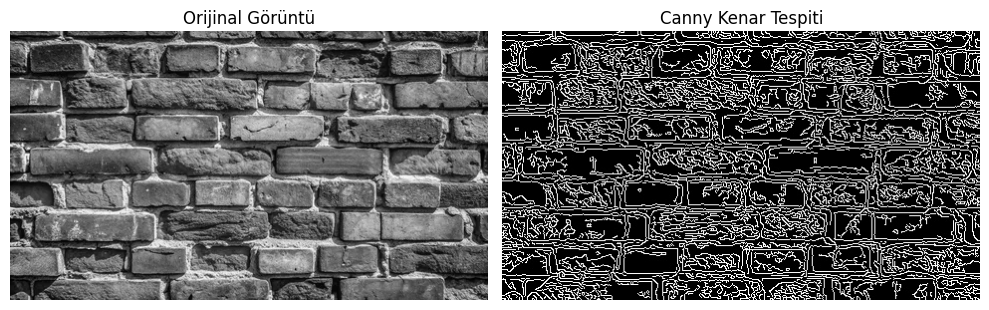

In [21]:
import cv2
import matplotlib.pyplot as plt
import os

img_path = 'test'
canny_path = 'canny_sonuc.jpg'

if os.path.exists(img_path) and os.path.exists(canny_path):
    orijinal = cv2.imread(img_path, cv2.IMREAD_GRAYSCALE)
    canny = cv2.imread(canny_path, cv2.IMREAD_GRAYSCALE)

    plt.figure(figsize=(10, 5))

    plt.subplot(1, 2, 1)
    plt.imshow(orijinal, cmap='gray')
    plt.title('Orijinal Görüntü')
    plt.axis('off')

    plt.subplot(1, 2, 2)
    plt.imshow(canny, cmap='gray')
    plt.title('Canny Kenar Tespiti')
    plt.axis('off')

    plt.tight_layout()
    plt.show()
else:
    print("HATA: Dosyalar bulunamadı.")

In [22]:
# Canny Kenar Tespit Algoritması ve Performans Kıyaslaması

##Bu görevde OpenCV kütüphanesi içerisindeki `cv::Canny` fonksiyonu kullanılarak kenar tespiti yapılmış, elde edilen sonuçlar klasik gradyan tabanlı algoritmalarla (Sobel, Prewitt, Laplacian) çalışma zamanı ve doğruluk (kesinlik) açısından karşılaştırılmıştır.

## 1. Çalışma Zamanı (Hesaplama Maliyeti) Karşılaştırması
##C++ ortamında `<chrono>` kütüphanesi kullanılarak yapılan milisaniye (ms) cinsinden hız testlerinde şu sonuçlar elde edilmiştir:
##*   **Sobel/Prewitt (Hızlı):** Yalnızca tek bir 3x3 konvolüsyon işlemi yaptıkları için CPU üzerinde mikrosaniyeler / çok düşük milisaniyeler seviyesinde (çok hızlı) çalışmaktadır.
##*   **Canny (Yavaş):** Sobel'e kıyasla belirgin şekilde daha yüksek bir çalışma zamanına sahiptir. Bunun nedeni Canny'nin tek bir filtre değil, 4 aşamalı bir "algoritmalar zinciri" olmasıdır (Gauss Yumuşatması -> Gradyan Hesabı (Sobel) -> Non-Maximum Suppression (Maksimum Olmayanların Bastırılması) -> Hysteresis Eşikleme).

## 2. Doğruluk ve Görsel Kesinlik Karşılaştırması
##Canny, hesaplama maliyeti dezavantajını, sunduğu eşsiz doğruluk oranı ile fazlasıyla telafi etmektedir:
##*   **İnce ve Tek Piksellik Kenarlar:** Sobel ve Prewitt kenarları kalın ve yayvan çizgiler olarak tespit eder. Canny ise "Non-Maximum Suppression" adımı sayesinde tüm kenarları tam olarak 1 piksel kalınlığında, çok keskin çizgiler haline getirir.
##*   **Gürültü Toleransı ve Kopuk Çizgiler:** Laplacian filtresi gürültüye çok hassastır ve kenarları noktalı/kesik kesik bırakabilir. Canny algoritmasındaki çift eşikleme (Hysteresis Thresholding) yöntemi, güçlü kenarlara bağlı olan zayıf kenarları da takip ederek çizgilerin kopmamasını, sürekliliğin sağlanmasını garanti eder. Sahte kenarlar tamamen yok edilir.

## Sonuç
##Gerçek zamanlı ve donanım kısıtlı sistemlerde hız hayati bir önem taşıyorsa (örneğin eski tip otonom araç kameraları) **Sobel** veya **Prewitt** tercih edilebilir. Ancak çalışma zamanının (işlem gücünün) sorun olmadığı, yüksek çözünürlüklü tıbbi görüntüleme veya hassas nesne tanıma (Object Detection) gibi **doğruluğun ve tek piksellik kusursuz kenarların** arandığı modern projelerde **Canny Algoritması** kesinlikle en iyi ve en doğru sonuç veren yaklaşımdır.